<a href="https://colab.research.google.com/github/silpia24/Basdat/blob/main/proyekuts2_2412510030_Nurul_Silpia_Sipongi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 Informasi Dataset  
**Titik Panas (Hotspot) Karhutla Indonesia**

### Insight

| Aspek | Keterangan |
|-------|------------|
| **Nama** | Nurul Silpia |
| **NIM** | 2412510030 |
| **Mata Kuliah** | Analisa Big Data – S3 |
| **Tugas** | Proyek UTS-02 |
| **Metode Pengumpulan** | API Crawling |
| **Sumber Data** | [SiPongi+ Sistem Pemantauan Karhutla](https://sipongi.gakkum.kehutanan.go.id/) |
| **Endpoint API** | `https://opsroom.sipongidata.my.id/api/opsroom/indoHotspot` |
| **Format Output** | XLSX |
| **Periode Data** | 19 Oktober 2026 – 19 November 2026 (1 Bulan) |
| **Wilayah** | Indonesia (`IN`) |
| **Satelit** | NASA-MODIS, NASA-NOAA20, NASA-NOAA21 |
| **Tingkat Kepercayaan** | High |

---

### Deskripsi Dataset

Dataset ini memuat rekaman koordinat titik panas (hotspot) yang terdeteksi oleh sensor satelit sebagai indikasi awal potensi kebakaran hutan dan lahan (Karhutla) di wilayah daratan Indonesia. Data dikumpulkan melalui API resmi SiPongi+ dengan menerapkan filter tingkat kepercayaan tinggi (High Confidence), sehingga hanya deteksi yang memiliki keyakinan tinggi sebagai kebakaran aktif yang direkam.

---

### Parameter Pencarian API

Data ditarik dengan parameter berikut:

- **Wilayah** : Indonesia (`IN`)
- **Rentang Waktu** : 19 Oktober 2026 – 19 November 2026
- **Satelit Pendeteksi** : NASA-MODIS, NASA-NOAA20, NASA-NOAA21
- **Tingkat Kepercayaan** : High

---

### Variabel Utama

| Nama Kolom | Tipe Data | Deskripsi |
|------------|-----------|-----------|
| `hs_id` | String | String timestamp dari satelit (bukan ID unik fisik per kejadian tunggal) |
| `date_hotspot` | String | Tanggal dan waktu UTC yang dikonversi ke format standar YYYY-MM-DD HH:MM:SS |
| `sumber` | String | Satelit/sensor yang mendeteksi anomali panas (contoh: NASA-MODIS) |
| `lat` | Float | Garis lintang (*latitude*) lokasi titik panas |
| `long` | Float | Garis bujur (*longitude*) lokasi titik panas |
| `counter` | Integer | Frekuensi deteksi berulang pada koordinat yang sama oleh sensor satelit  |
| `nama_provinsi` | String | Nama provinsi lokasi titik panas (diisi 'TIDAK DIKETAHUI' jika kosong) |
| `kabkota` | String | Nama kabupaten/kota lokasi titik panas (diisi 'TIDAK DIKETAHUI' jika kosong) |
| `kecamatan` | String | Nama kecamatan lokasi titik panas (diisi 'TIDAK DIKETAHUI' jika kosong) |
| `desa` | String | Nama desa lokasi titik panas (diisi 'TIDAK DIKETAHUI' jika kosong) |
| `confidence` | Integer | Skor persentase tingkat keyakinan (0–100) bahwa titik tersebut merupakan api nyata |
| `confidence_level` | String | Kategori tingkat kepastian dari algoritma satelit (`low`, `medium`, `high`) |
---

In [ ]:
import requests
import pandas as pd
import json
import numpy as np
import sys
import re
from collections import Counter
from textwrap import fill
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import data_table
data_table.enable_dataframe_formatter()

In [ ]:
# API CONFIG
url = 'https://opsroom.sipongidata.my.id/api/opsroom/indoHotspot'
params = {
    'wilayah': 'IN',
    'filterperiode': 'true',
    'from': '2026-10-19',
    'to': '2026-11-19',
    'late': 'custom',
    'satelit[]': ['NASA-MODIS', 'NASA-NOAA20', 'NASA-NOAA21'],
    'confidence[]': ['high']
}

# Fetch Data
try:
    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()
    data = response.json()
    print("Preview Data: \n")
    print(json.dumps(data['features'][:2] if 'features' in data else data, indent=1))
except Exception as e:
    print(f"An error occurred during API fetch: {e}")
    sys.exit("The process was terminated due to a failure to retrieve data from the API.")

Preview Data: 

[
 {
  "type": "Feature",
  "geometry": {
   "type": "Point",
   "coordinates": [
    114.74923,
    -2.64328
   ]
  },
  "properties": {
   "hs_id": "2026-11-04T20:08:00.000000Z",
   "date_hotspot_ori": "2026-11-04T20:08:00.000000Z",
   "provinsi_id": 13,
   "lat": -2.64328,
   "long": 114.74923,
   "sumber": "NASA-MODIS",
   "ori_sumber": null,
   "date_hotspot": "Kamis, 05 November 2026 03:08:00",
   "desa_id": null,
   "counter": 2,
   "confidence": 82,
   "confidence_level": "high",
   "kawasan": "",
   "desa": "Bina Karya",
   "kecamatan": "Kapuas Murung",
   "kabkota": "Kapuas",
   "nama_provinsi": "Kalimantan Tengah",
   "pulau": "",
   "route_create": "https://opsroom.sipongidata.my.id/daops/laporan/groundcheck/create/form"
  }
 },
 {
  "type": "Feature",
  "geometry": {
   "type": "Point",
   "coordinates": [
    116.22961,
    0.60064
   ]
  },
  "properties": {
   "hs_id": "2026-10-30T07:56:00.000000Z",
   "date_hotspot_ori": "2026-10-30T07:56:00.000000Z",
 

In [ ]:
# Extract the “properties” column from each feature into a DataFrame
if data and 'features' in data:
    records = [feature['properties'] for feature in data['features']]
    df_raw = pd.DataFrame(records)
    print(f"Initial Dimention: {df_raw.shape[0]} row, {df_raw.shape[1]} column")
    display(df_raw.head())
else:
    print("Data is missing or failed to load.")

Initial Dimention: 7633 row, 19 column


,hs_id,date_hotspot_ori,provinsi_id,lat,long,sumber,ori_sumber,date_hotspot,desa_id,counter,confidence,confidence_level,kawasan,desa,kecamatan,kabkota,nama_provinsi,pulau,route_create
0,2026-11-04T20:08:00.000000Z,2026-11-04T20:08:00.000000Z,13,-2.64328,114.74923,NASA-MODIS,None,"Kamis, 05 November 2026 03:08:00",None,2,82,high,,Bina Karya,Kapuas Murung,Kapuas,Kalimantan Tengah,,https://opsroom.sipongidata.my.id/daops/lapora...
1,2026-10-30T07:56:00.000000Z,2026-10-30T07:56:00.000000Z,14,0.60064,116.22961,NASA-MODIS,None,"Jumat, 30 Oktober 2026 14:56:00",None,1,82,high,,Umaq Tukung,Tabang,Kutai Kartanegara,Kalimantan Timur,,https://opsroom.sipongidata.my.id/daops/lapora...
2,2026-10-21T13:21:00.000000Z,2026-10-21T13:21:00.000000Z,11,-2.82790,110.68661,NASA-MODIS,None,"Rabu, 21 Oktober 2026 20:21:00",None,1,82,high,,Air Hitam Besar,Kendawangan,Ketapang,Kalimantan Barat,,https://opsroom.sipongidata.my.id/daops/lapora...
3,2026-10-23T08:24:00.000000Z,2026-10-23T08:24:00.000000Z,13,-3.17586,112.54284,NASA-MODIS,None,"Jumat, 23 Oktober 2026 15:24:00",None,1,82,high,,Mekar Indah,Seruyan Hilir Timur,Seruyan,Kalimantan Tengah,,https://opsroom.sipongidata.my.id/daops/lapora...
4,2026-10-20T12:44:00.000000Z,2026-10-20T12:44:00.000000Z,14,2.32936,116.99191,NASA-MODIS,None,"Selasa, 20 Oktober 2026 19:44:00",None,1,82,high,,Long Ayan,Segah,Berau,Kalimantan Timur,,https://opsroom.sipongidata.my.id/daops/lapora...


In [ ]:
pd.set_option('future.no_silent_downcasting', True)

selected_cols = ['nama_provinsi', 'kabkota', 'kecamatan', 'desa', 'confidence_level']
df_clean = df_raw.copy()
df_clean[selected_cols] = df_clean[selected_cols].replace(r'^\s*$', np.nan, regex=True).infer_objects(copy=False)

audit_df = pd.DataFrame({
    'Data Type': df_clean.dtypes,
    'Count Null': df_clean.isnull().sum(),
    'Percentage Null (%)': (df_clean.isnull().sum() / len(df_clean) * 100).round(2),
    'Unique Value': df_clean.nunique()
})
display(audit_df)

,Data Type,Count Null,Percentage Null (%),Unique Value
hs_id,object,0,0.0,519
date_hotspot_ori,object,0,0.0,519
provinsi_id,int64,0,0.0,31
lat,float64,0,0.0,7550
long,float64,0,0.0,7570
sumber,object,0,0.0,3
ori_sumber,object,7633,100.0,0
date_hotspot,object,0,0.0,519
desa_id,object,7633,100.0,0
counter,int64,0,0.0,20


In [ ]:
# CLEANSING DATA
features_list = data.get('features', []) if isinstance(data, dict) else []

if isinstance(features_list, list) and len(features_list) > 0:
    extracted_data = [item.get("properties", {}) for item in features_list]
    df_clean = pd.DataFrame(extracted_data)

    # Time conversion from raw data
    if 'date_hotspot_ori' in df_clean.columns:
        df_clean['date_hotspot'] = pd.to_datetime(df_clean['date_hotspot_ori']).dt.strftime('%Y-%m-%d %H:%M:%S')

    # 1. Pilih kolom penting
    selected_columns = [
        'hs_id',
        'date_hotspot',
        'sumber',
        'lat',
        'long',
        'counter',
        'nama_provinsi',
        'kabkota',
        'kecamatan',
        'desa',
        'confidence',
        'confidence_level'
    ]
    df_clean = df_clean[selected_columns]

    # 2. Delete the row if all columns are empty
    df_clean = df_clean.dropna(how='all')

    # 3. Only drops if the ‘lat’ or ‘long’ fields are empty (hs_id is a timestamp, not a unique physical ID)
    df_clean = df_clean.dropna(subset=['lat', 'long'])

    # 4. Fill in the missing values for the direct regions
    regional_cols = ['nama_provinsi', 'kabkota', 'kecamatan', 'desa']
    df_clean[regional_cols] = df_clean[regional_cols].fillna('TIDAK DIKETAHUI')

    display(df_clean.head())
    print(df_clean.info())
else:
    print("Warning: 'features_list' kosong. Silakan jalankan kembali penarikan data API di atas.")

,hs_id,date_hotspot,sumber,lat,long,counter,nama_provinsi,kabkota,kecamatan,desa,confidence,confidence_level
0,2026-11-04T20:08:00.000000Z,2026-11-04 20:08:00,NASA-MODIS,-2.64328,114.74923,2,Kalimantan Tengah,Kapuas,Kapuas Murung,Bina Karya,82,high
1,2026-10-30T07:56:00.000000Z,2026-10-30 07:56:00,NASA-MODIS,0.60064,116.22961,1,Kalimantan Timur,Kutai Kartanegara,Tabang,Umaq Tukung,82,high
2,2026-10-21T13:21:00.000000Z,2026-10-21 13:21:00,NASA-MODIS,-2.82790,110.68661,1,Kalimantan Barat,Ketapang,Kendawangan,Air Hitam Besar,82,high
3,2026-10-23T08:24:00.000000Z,2026-10-23 08:24:00,NASA-MODIS,-3.17586,112.54284,1,Kalimantan Tengah,Seruyan,Seruyan Hilir Timur,Mekar Indah,82,high
4,2026-10-20T12:44:00.000000Z,2026-10-20 12:44:00,NASA-MODIS,2.32936,116.99191,1,Kalimantan Timur,Berau,Segah,Long Ayan,82,high


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7633 entries, 0 to 7632
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   hs_id             7633 non-null   object 
 1   date_hotspot      7633 non-null   object 
 2   sumber            7633 non-null   object 
 3   lat               7633 non-null   float64
 4   long              7633 non-null   float64
 5   counter           7633 non-null   int64  
 6   nama_provinsi     7633 non-null   object 
 7   kabkota           7633 non-null   object 
 8   kecamatan         7633 non-null   object 
 9   desa              7633 non-null   object 
 10  confidence        7633 non-null   int64  
 11  confidence_level  7633 non-null   object 
dtypes: float64(2), int64(2), object(8)
memory usage: 715.7+ KB
None


In [ ]:
# Export data
df_clean.to_excel('proyekuts2-2412510030-Nurul_Silpia-Sipongi.xlsx', index=False)
print(f"\nSuccessfully exported data to .xlsx")


Successfully exported data to .xlsx


# Analisis Data

In [ ]:
# ===== 0. PREPARATION =====
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

try:
    df_clean
except NameError:
    df_clean = pd.read_excel("proyekuts2-2412510030-Nurul_Silpia-Sipongi.xlsx")

df = df_clean.copy()

# date_hotspot is derived from date_hotspot_ori (UTC) -> convert to WIB (UTC+7)
df["waktu_wib"] = pd.to_datetime(df["date_hotspot"]) + pd.Timedelta(hours=7)
df["tanggal"] = df["waktu_wib"].dt.normalize()
df["jam"] = df["waktu_wib"].dt.hour

BULAN = ["Januari", "Februari", "Maret", "April", "Mei", "Juni", "Juli",
         "Agustus", "September", "Oktober", "November", "Desember"]

def tgl(d):
    d = pd.Timestamp(d)
    return f"{d.day} {BULAN[d.month - 1]} {d.year}"

def fmt(n):            # 7633 -> 7.633
    return f"{int(n):,}".replace(",", ".")

def dec(x, n=2):       # 12.5 -> 12,50
    return f"{x:.{n}f}".replace(".", ",")

def tabel_frekuensi(series, nama, urut_index=False):
    f = series.value_counts()
    f = f.sort_index() if urut_index else f
    f = f.rename("Frekuensi").to_frame()
    f["Persentase (%)"] = (f["Frekuensi"] / f["Frekuensi"].sum() * 100).round(2)
    f["Kumulatif (%)"] = (f["Frekuensi"].cumsum() / f["Frekuensi"].sum() * 100).round(2)
    f.index.name = nama
    return f

def interpretasi(teks):
    print("INTERPRETASI:\n")
    print(fill(teks, 110))

def simpan(nama_file):
    plt.tight_layout()
    plt.savefig(nama_file, dpi=150, bbox_inches="tight")
    plt.show()

total = len(df)
n_prov = df["nama_provinsi"].nunique()
awal, akhir = df["waktu_wib"].min(), df["waktu_wib"].max()
print(f"Total data: {fmt(total)} baris | Periode (WIB): {tgl(awal)} - {tgl(akhir)}")

Total data: 7.633 baris | Periode (WIB): 19 Oktober 2026 - 19 November 2026


## 1. ANALISIS FREKUENSI

,Frekuensi,Persentase (%),Kumulatif (%)
Provinsi,,,
Kalimantan Tengah,2421,31.72,31.72
Papua Selatan,1416,18.55,50.27
Sumatera Selatan,591,7.74,58.01
Kalimantan Timur,509,6.67,64.68
Sulawesi Tenggara,387,5.07,69.75
Kalimantan Barat,386,5.06,74.81
Sulawesi Tengah,359,4.70,79.51
Sulawesi Selatan,263,3.45,82.96
Kalimantan Selatan,225,2.95,85.90


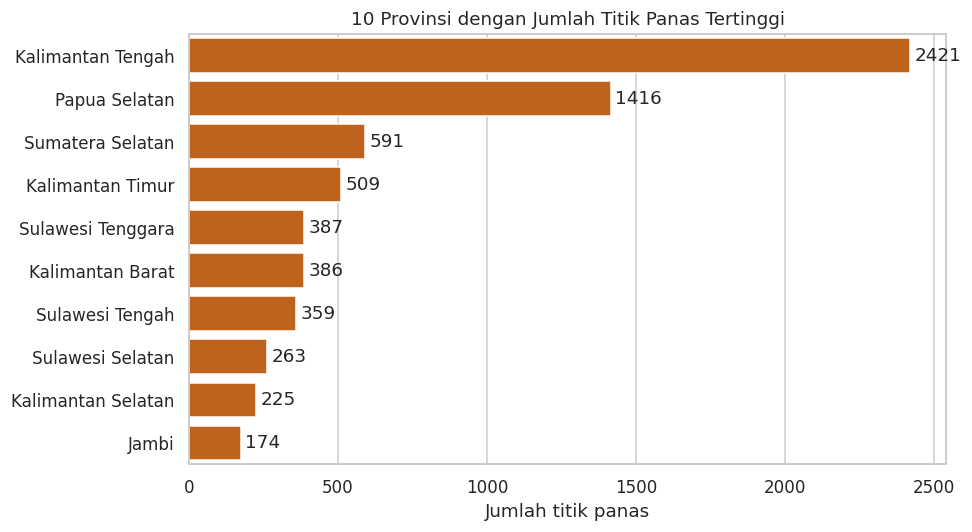

INTERPRETASI:

Dari 7.633 titik panas dengan tingkat kepercayaan tinggi yang terdeteksi pada 19 Oktober 2026 sampai 19
November 2026, titik panas terbanyak berada di Provinsi Kalimantan Tengah (2.421 titik; 31,72%), diikuti Papua
Selatan (1.416 titik; 18,55%) dan Sumatera Selatan (591 titik; 7,74%). Tiga provinsi teratas menyumbang 58,01%
dari seluruh titik panas, sementara 28 provinsi lainnya berbagi sisanya. Grafik batang menunjukkan sebaran
titik panas tidak merata dan terkonsentrasi pada beberapa provinsi, sehingga wilayah tersebut perlu menjadi
prioritas pemantauan dan pencegahan karhutla.


In [ ]:
# ===== 1.1 FREQUENCY BY PROVINCE (bar chart) =====
frek_prov = tabel_frekuensi(df["nama_provinsi"], "Provinsi")
display(frek_prov)

top10 = frek_prov.head(10)
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=top10["Frekuensi"].values, y=top10.index, orient="h", color="#d95f02", ax=ax)
ax.bar_label(ax.containers[0], padding=3)
ax.set_title("10 Provinsi dengan Jumlah Titik Panas Tertinggi")
ax.set_xlabel("Jumlah titik panas"); ax.set_ylabel("")
simpan("grafik_1_provinsi.png")

p = frek_prov
interpretasi(
    f"Dari {fmt(total)} titik panas dengan tingkat kepercayaan tinggi yang terdeteksi pada {tgl(awal)} sampai {tgl(akhir)}, "
    f"titik panas terbanyak berada di Provinsi {p.index[0]} ({fmt(p['Frekuensi'].iloc[0])} titik; {dec(p['Persentase (%)'].iloc[0])}%), "
    f"diikuti {p.index[1]} ({fmt(p['Frekuensi'].iloc[1])} titik; {dec(p['Persentase (%)'].iloc[1])}%) dan "
    f"{p.index[2]} ({fmt(p['Frekuensi'].iloc[2])} titik; {dec(p['Persentase (%)'].iloc[2])}%). "
    f"Tiga provinsi teratas menyumbang {dec(p['Persentase (%)'].head(3).sum())}% dari seluruh titik panas, "
    f"sementara {n_prov - 3} provinsi lainnya berbagi sisanya. Grafik batang menunjukkan sebaran titik panas "
    f"tidak merata dan terkonsentrasi pada beberapa provinsi, sehingga wilayah tersebut perlu menjadi prioritas "
    f"pemantauan dan pencegahan karhutla.")

,Frekuensi,Persentase (%),Kumulatif (%)
Kabupaten/Kota (Provinsi),,,
Merauke (Papua Selatan),1267,16.60,16.60
Pulang Pisau (Kalimantan Tengah),528,6.92,23.52
Kapuas (Kalimantan Tengah),466,6.11,29.62
Seruyan (Kalimantan Tengah),428,5.61,35.23
Ketapang (Kalimantan Barat),383,5.02,40.25
Ogan Komering Ilir (Sumatera Selatan),383,5.02,45.26
Kotawaringin Timur (Kalimantan Tengah),249,3.26,48.53
Katingan (Kalimantan Tengah),243,3.18,51.71
Kotawaringin Barat (Kalimantan Tengah),234,3.07,54.78


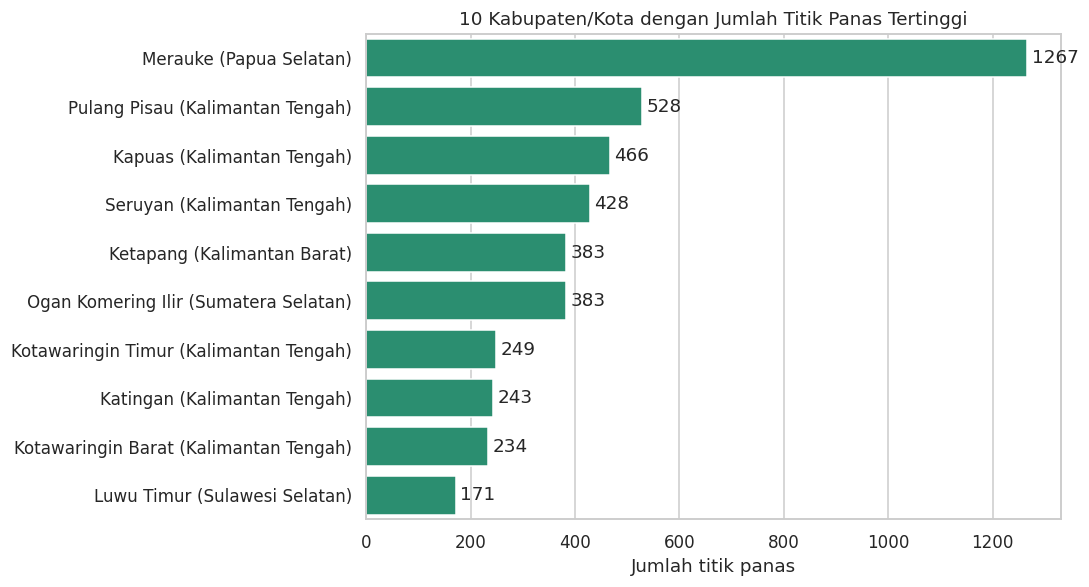

INTERPRETASI:

Pada tingkat kabupaten/kota, titik panas terbanyak terdapat di Merauke (Papua Selatan) (1.267 titik; 16,60%),
disusul Pulang Pisau (Kalimantan Tengah) (528 titik) dan Kapuas (Kalimantan Tengah) (466 titik). Sepuluh
kabupaten/kota teratas menyumbang 57,03% dari total titik panas dari 208 kabupaten/kota yang terdeteksi, yang
menandakan titik panas terpusat di sejumlah kecil wilayah.


In [ ]:
# ===== 1.2 FREQUENCY BY REGION/CITY =====
df["kabkota_prov"] = df["kabkota"] + " (" + df["nama_provinsi"] + ")"
frek_kab = tabel_frekuensi(df["kabkota_prov"], "Kabupaten/Kota (Provinsi)")
display(frek_kab.head(15))

t10 = frek_kab.head(10)
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(x=t10["Frekuensi"].values, y=t10.index, orient="h", color="#1b9e77", ax=ax)
ax.bar_label(ax.containers[0], padding=3)
ax.set_title("10 Kabupaten/Kota dengan Jumlah Titik Panas Tertinggi")
ax.set_xlabel("Jumlah titik panas"); ax.set_ylabel("")
simpan("grafik_2_kabkota.png")

k = frek_kab
interpretasi(
    f"Pada tingkat kabupaten/kota, titik panas terbanyak terdapat di {k.index[0]} ({fmt(k['Frekuensi'].iloc[0])} titik; "
    f"{dec(k['Persentase (%)'].iloc[0])}%), disusul {k.index[1]} ({fmt(k['Frekuensi'].iloc[1])} titik) dan "
    f"{k.index[2]} ({fmt(k['Frekuensi'].iloc[2])} titik). Sepuluh kabupaten/kota teratas menyumbang "
    f"{dec(k['Persentase (%)'].head(10).sum())}% dari total titik panas dari {df['kabkota_prov'].nunique()} kabupaten/kota "
    f"yang terdeteksi, yang menandakan titik panas terpusat di sejumlah kecil wilayah.")

,Frekuensi,Persentase (%),Kumulatif (%)
Satelit,,,
NASA-MODIS,4886,64.01,64.01
NASA-NOAA20,2167,28.39,92.40
NASA-NOAA21,580,7.60,100.00


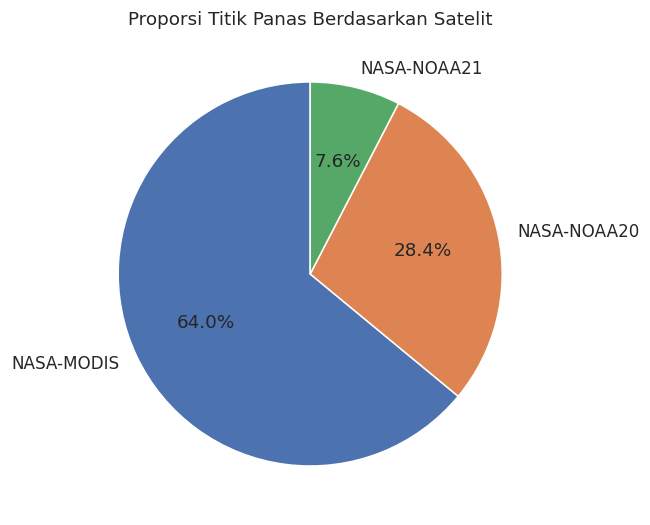

INTERPRETASI:

Berdasarkan sumber satelit, NASA-MODIS paling banyak mendeteksi titik panas (4.886 titik; 64,01%), diikuti
NASA-NOAA20 (28,39%) dan NASA-NOAA21 (7,60%). Perbedaan proporsi ini dipengaruhi oleh jumlah satelit, jadwal
lintasan, dan sensitivitas sensor masing-masing, bukan oleh perbedaan kondisi di lapangan.


In [ ]:
# ===== 1.3 FREQUENCY BY SATELIT (pie chart) =====
frek_sat = tabel_frekuensi(df["sumber"], "Satelit")
display(frek_sat)

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(frek_sat["Frekuensi"], labels=frek_sat.index, autopct="%1.1f%%", startangle=90,
       wedgeprops={"edgecolor": "white"})
ax.set_title("Proporsi Titik Panas Berdasarkan Satelit")
simpan("grafik_3_satelit.png")

s = frek_sat
interpretasi(
    f"Berdasarkan sumber satelit, {s.index[0]} paling banyak mendeteksi titik panas ({fmt(s['Frekuensi'].iloc[0])} titik; "
    f"{dec(s['Persentase (%)'].iloc[0])}%), diikuti {s.index[1]} ({dec(s['Persentase (%)'].iloc[1])}%) dan "
    f"{s.index[2]} ({dec(s['Persentase (%)'].iloc[2])}%). Perbedaan proporsi ini dipengaruhi oleh jumlah satelit, "
    f"jadwal lintasan, dan sensitivitas sensor masing-masing, bukan oleh perbedaan kondisi di lapangan.")

,Jumlah Titik Panas
Tanggal,
2026-10-19,401
2026-10-20,780
2026-10-21,867
2026-10-22,839
2026-10-23,1627
2026-10-24,289
2026-10-25,93
2026-10-26,58
2026-10-27,72


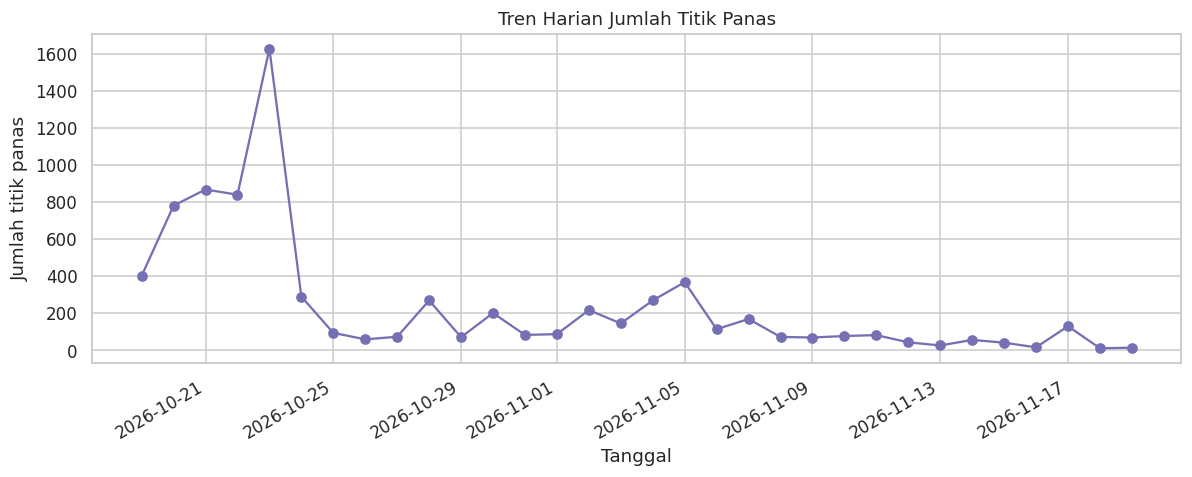

INTERPRETASI:

Secara harian, rata-rata terdeteksi 238,5 titik panas per hari. Jumlah tertinggi terjadi pada 23 Oktober 2026
(1.627 titik) dan terendah pada 18 November 2026 (10 titik). Rata-rata paruh pertama periode adalah 380,8
titik per hari dibandingkan 96,3 titik per hari pada paruh kedua, sehingga tren titik panas cenderung menurun.


In [ ]:
# ===== 1.4 TREN HARIAN =====
rentang = pd.date_range(df["tanggal"].min(), df["tanggal"].max())
harian = df.groupby("tanggal").size().reindex(rentang, fill_value=0)
harian.index.name = "Tanggal"; harian.name = "Jumlah Titik Panas"
display(harian.to_frame())

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(harian.index, harian.values, marker="o", color="#7570b3")
ax.set_title("Tren Harian Jumlah Titik Panas")
ax.set_xlabel("Tanggal"); ax.set_ylabel("Jumlah titik panas")
fig.autofmt_xdate()
simpan("grafik_4_harian.png")

puncak, terendah = harian.idxmax(), harian.idxmin()
h = len(harian) // 2
m1, m2 = harian.iloc[:h].mean(), harian.iloc[h:].mean()
arah = "meningkat" if m2 > m1 * 1.05 else ("menurun" if m2 < m1 * 0.95 else "relatif stabil")
interpretasi(
    f"Secara harian, rata-rata terdeteksi {dec(harian.mean(), 1)} titik panas per hari. Jumlah tertinggi terjadi pada "
    f"{tgl(puncak)} ({fmt(harian.max())} titik) dan terendah pada {tgl(terendah)} ({fmt(harian.min())} titik). "
    f"Rata-rata paruh pertama periode adalah {dec(m1, 1)} titik per hari dibandingkan {dec(m2, 1)} titik per hari "
    f"pada paruh kedua, sehingga tren titik panas cenderung {arah}.")

,Jam (WIB),Frekuensi,Persentase (%)
0,00:00-00:59,116,1.52
1,01:00-01:59,238,3.12
2,02:00-02:59,153,2.00
3,03:00-03:59,827,10.83
4,04:00-04:59,14,0.18
5,05:00-05:59,3,0.04
6,06:00-06:59,17,0.22
7,07:00-07:59,63,0.83
8,08:00-08:59,62,0.81
9,09:00-09:59,0,0.00


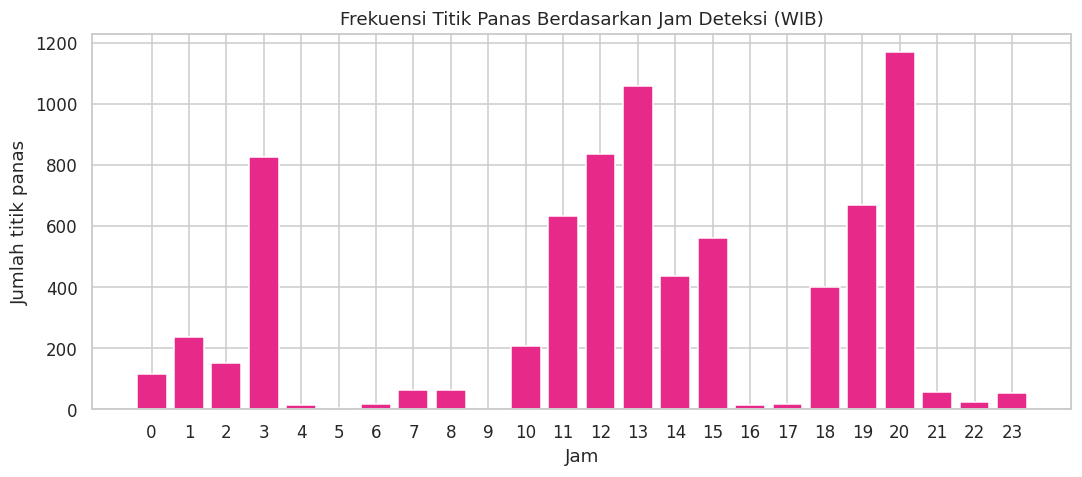

INTERPRETASI:

Berdasarkan jam deteksi, titik panas paling banyak tercatat pada pukul 20.00 WIB (1.171 titik), diikuti pukul
13.00 dan 12.00 WIB. Tiga jam teratas ini menyumbang 40,18% dari seluruh deteksi. Perlu dicatat bahwa waktu
ini adalah waktu satelit melintas dan merekam anomali panas, bukan waktu api mulai menyala.


In [ ]:
# ===== 1.5 FREKUENSI PER JAM DETEKSI (WIB) =====
jam = df["jam"].value_counts().reindex(range(24), fill_value=0).sort_index()
tabel_jam = pd.DataFrame({
    "Jam (WIB)": [f"{x:02d}:00-{x:02d}:59" for x in jam.index],
    "Frekuensi": jam.values,
    "Persentase (%)": (jam.values / jam.sum() * 100).round(2),
})
display(tabel_jam)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(jam.index, jam.values, color="#e7298a")
ax.set_xticks(range(24))
ax.set_title("Frekuensi Titik Panas Berdasarkan Jam Deteksi (WIB)")
ax.set_xlabel("Jam"); ax.set_ylabel("Jumlah titik panas")
simpan("grafik_5_jam.png")

t3 = jam.sort_values(ascending=False).head(3)
interpretasi(
    f"Berdasarkan jam deteksi, titik panas paling banyak tercatat pada pukul {t3.index[0]:02d}.00 WIB "
    f"({fmt(t3.iloc[0])} titik), diikuti pukul {t3.index[1]:02d}.00 dan {t3.index[2]:02d}.00 WIB. Tiga jam teratas ini "
    f"menyumbang {dec(t3.sum() / jam.sum() * 100)}% dari seluruh deteksi. Perlu dicatat bahwa waktu ini adalah waktu satelit "
    f"melintas dan merekam anomali panas, bukan waktu api mulai menyala.")

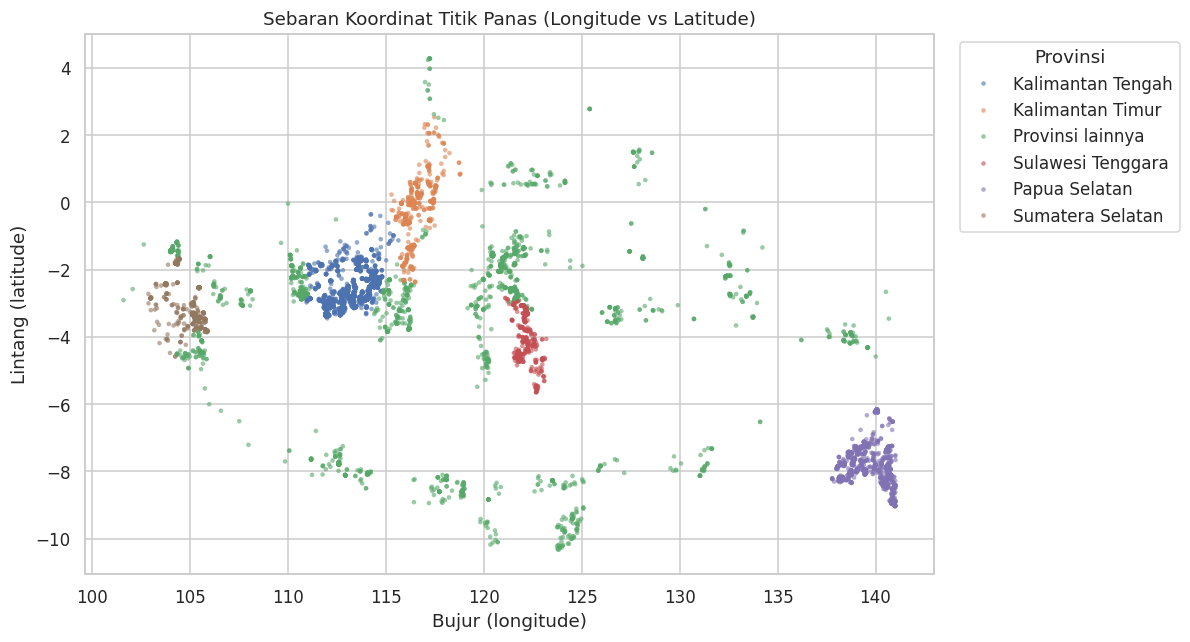

INTERPRETASI:

Scatter plot memperlihatkan titik panas tersebar pada lintang -10,33 hingga 4,28 dan bujur 101,60 hingga
141,02. Warna menunjukkan bahwa titik panas membentuk kelompok-kelompok yang padat di wilayah Kalimantan
Tengah, Papua Selatan, Sumatera Selatan, sedangkan provinsi lain tampak lebih menyebar. Pola ini menegaskan
hasil tabel frekuensi bahwa titik panas terkonsentrasi secara spasial.


In [ ]:
# ===== 1.6 COORDINATE DISTRIBUTION (scatter plot) =====
top5 = frek_prov.index[:5]
df["grup_prov"] = np.where(df["nama_provinsi"].isin(top5), df["nama_provinsi"], "Provinsi lainnya")

fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(data=df, x="long", y="lat", hue="grup_prov", s=9, alpha=0.6, linewidth=0, ax=ax)
ax.set_title("Sebaran Koordinat Titik Panas (Longitude vs Latitude)")
ax.set_xlabel("Bujur (longitude)"); ax.set_ylabel("Lintang (latitude)")
ax.legend(title="Provinsi", bbox_to_anchor=(1.02, 1), loc="upper left")
simpan("grafik_7_scatter.png")

interpretasi(
    f"Scatter plot memperlihatkan titik panas tersebar pada lintang {dec(df['lat'].min())} hingga {dec(df['lat'].max())} "
    f"dan bujur {dec(df['long'].min())} hingga {dec(df['long'].max())}. Warna menunjukkan bahwa titik panas membentuk "
    f"kelompok-kelompok yang padat di wilayah {', '.join(top5[:3])}, sedangkan provinsi lain tampak lebih menyebar. "
    f"Pola ini menegaskan hasil tabel frekuensi bahwa titik panas terkonsentrasi secara spasial.")

## Kesimpulan

In [ ]:
# ===== SUMMARY =====
p, s = frek_prov, frek_sat
kes = [
    f"1. Selama {tgl(awal)} sampai {tgl(akhir)} terdeteksi {fmt(total)} titik panas berkepercayaan tinggi di {n_prov} provinsi. "
    f"Sebarannya terkonsentrasi: {p.index[0]} ({dec(p['Persentase (%)'].iloc[0])}%), {p.index[1]} ({dec(p['Persentase (%)'].iloc[1])}%) dan "
    f"{p.index[2]} ({dec(p['Persentase (%)'].iloc[2])}%) menyumbang {dec(p['Persentase (%)'].head(3).sum())}% dari total.",
    f"2. Kabupaten/kota dengan titik panas terbanyak adalah {frek_kab.index[0]} ({fmt(frek_kab['Frekuensi'].iloc[0])} titik).",
    f"3. Satelit {s.index[0]} paling banyak mendeteksi titik panas ({dec(s['Persentase (%)'].iloc[0])}%).",
    f"4. Secara temporal, puncak deteksi terjadi pada {tgl(puncak)} ({fmt(harian.max())} titik) dengan rata-rata {dec(harian.mean(), 1)} titik per hari, "
    f"dan deteksi terbanyak pada pukul {t3.index[0]:02d}.00 WIB.",
]
print("DRAFT KESIMPULAN:\n")
for baris in kes:
    print(fill(baris, 110, subsequent_indent="   "), "\n")

DRAFT KESIMPULAN:

1. Selama 19 Oktober 2026 sampai 19 November 2026 terdeteksi 7.633 titik panas berkepercayaan tinggi di 31
   provinsi. Sebarannya terkonsentrasi: Kalimantan Tengah (31,72%), Papua Selatan (18,55%) dan Sumatera
   Selatan (7,74%) menyumbang 58,01% dari total. 

2. Kabupaten/kota dengan titik panas terbanyak adalah Merauke (Papua Selatan) (1.267 titik). 

3. Satelit NASA-MODIS paling banyak mendeteksi titik panas (64,01%). 

4. Secara temporal, puncak deteksi terjadi pada 23 Oktober 2026 (1.627 titik) dengan rata-rata 238,5 titik per
   hari, dan deteksi terbanyak pada pukul 20.00 WIB. 

